In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.model_selection import KFold
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, SplineTransformer
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import root_mean_squared_error

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor


# Part 1


In [2]:
auto = pd.read_csv("Auto.csv", na_values="?").dropna().reset_index(drop=True)
auto.shape


(392, 9)

### Question 1


##### Part A


In [3]:
auto["cylinders"].value_counts()


cylinders
4    199
8    103
6     83
3      4
5      3
Name: count, dtype: int64

<Axes: xlabel='cylinders', ylabel='mpg'>

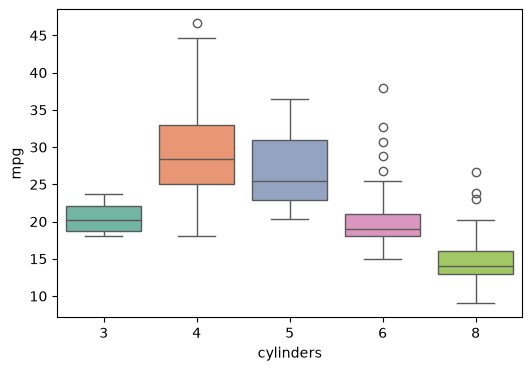

In [4]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=auto, x="cylinders", y="mpg", hue="cylinders", palette="Set2", legend=False)


##### Part B


In [5]:
def rollup(c):
    if c < 6:
        return "<6"
    if c == 6:
        return "6"
    return "8"

cyl_rollup = auto["cylinders"].map(rollup)
cyl_rollup.value_counts()


cylinders
<6    206
8     103
6      83
Name: count, dtype: int64

##### Part C


<Axes: xlabel='cyl_rollup', ylabel='mpg'>

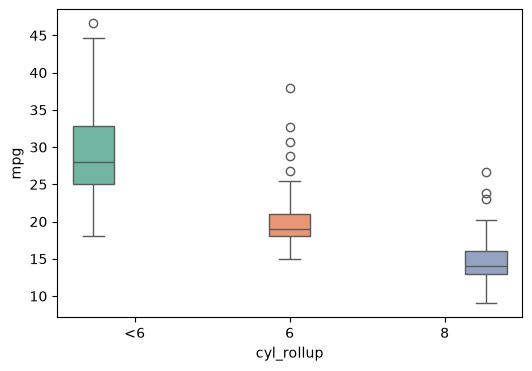

In [6]:
auto["cyl_rollup"] = pd.Categorical(cyl_rollup, categories=["<6", "6", "8"], ordered=True)

plt.figure(figsize=(6, 4))
sns.boxplot(data=auto, x="cyl_rollup", y="mpg", hue="cyl_rollup", palette="Set2", legend=False)


MPG decreases consistently from <6 cylinders to 6 cylinders to 8 cylinders. The medians go from around 28 for <6, to 19 for 6, to 14 for 8.


##### Part D


In [7]:
auto["name"].nunique()


301

There are 301 different car names and most only have one entry, so the variable itself is not very informative.


### Question 2


In [8]:
num = ["displacement", "horsepower", "weight", "acceleration", "year"]
X = auto[num]
y = auto["mpg"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

cv = KFold(n_splits=5, shuffle=True, random_state=42)


##### Part A


In [9]:
for k in range(1, 5):
    sfs = SequentialFeatureSelector(LinearRegression(), n_features_to_select=k,
                                    direction="forward", cv=cv,
                                    scoring="neg_root_mean_squared_error")
    sfs.fit(X_scaled, y)
    print(f"k={k}:", list(sfs.get_feature_names_out(num)))


k=1: ['weight']
k=2: ['weight', 'year']
k=3: ['displacement', 'weight', 'year']
k=4: ['displacement', 'horsepower', 'weight', 'year']


##### Part B


In [10]:
sfs_bwd = SequentialFeatureSelector(LinearRegression(), n_features_to_select=3,
                                    direction="backward", cv=cv,
                                    scoring="neg_root_mean_squared_error")
sfs_bwd.fit(X_scaled, y)
print("backward k=3:", list(sfs_bwd.get_feature_names_out(num)))


backward k=3: ['displacement', 'weight', 'year']


Forward and backward selection both returned the same three features, displacement, weight, and year. Neither method compares every combination of three predictors, only the ones that made it that far, so this does not guarantee they found the best three predictor model. It is very strong evidence though.


##### Part C


In [11]:
auto[["displacement", "horsepower", "weight"]].corr()


,displacement,horsepower,weight
displacement,1.000000,0.897257,0.932994
horsepower,0.897257,1.000000,0.864538
weight,0.932994,0.864538,1.000000


In [12]:
X_vif = sm.add_constant(auto[["displacement", "horsepower", "weight"]])

for i in range(1, X_vif.shape[1]):
    print(X_vif.columns[i], round(variance_inflation_factor(X_vif.values, i), 2))


displacement 10.31
horsepower 5.29
weight 7.96


The correlations between all three variables are very high and each VIF is also quite high with displacement over 10. This means the variables share a lot of their explanatory power and can be swapped for each other with minimal impact to the model. For backward selection we start with all the variables and given there is so much collinearity which one gets dropped could easily change. For forward selection the strongest will be picked first but after that the next variables won't provide much predictive power.


# Part 2


### Question 1


##### Part A


In [13]:
num_a = ["displacement", "weight", "year"]
cat = ["cyl_rollup", "origin"]

X_a = auto[num_a]
X_b = auto[num_a + cat]
y = auto["mpg"]

pre_a = make_column_transformer(
    (StandardScaler(), num_a),
)

pre_b = make_column_transformer(
    (StandardScaler(), num_a),
    (OneHotEncoder(drop="first"), cat),
)


In [14]:
X_a_train, X_a_test, y_train, y_test = train_test_split(X_a, y, test_size=0.2, random_state=42)
X_b_train, X_b_test, y_train_b, y_test_b = train_test_split(X_b, y, test_size=0.2, random_state=42)

model_a = make_pipeline(pre_a, LinearRegression()).fit(X_a_train, y_train)
model_b = make_pipeline(pre_b, LinearRegression()).fit(X_b_train, y_train_b)

rows = [
    {"model": "A",
     "train RMSE": root_mean_squared_error(y_train, model_a.predict(X_a_train)),
     "test RMSE": root_mean_squared_error(y_test, model_a.predict(X_a_test))},
    {"model": "B",
     "train RMSE": root_mean_squared_error(y_train_b, model_b.predict(X_b_train)),
     "test RMSE": root_mean_squared_error(y_test_b, model_b.predict(X_b_test))},
]
rmse_table = pd.DataFrame(rows).set_index("model")
rmse_table.round(3)


,train RMSE,test RMSE
model,,
A,3.460,3.261
B,3.226,3.089


##### Part B


Model B has a lower test and train RMSE, so I would say it is better.


### Question 2


##### Part A


In [15]:
methods = {
    "5-fold": KFold(n_splits=5, shuffle=True, random_state=42),
    "10-fold": KFold(n_splits=10, shuffle=True, random_state=42),
}

rows = []
for model_name in ["A", "B"]:
    if model_name == "A":
        model, Xm = model_a, X_a
    else:
        model, Xm = model_b, X_b
    row = {"model": model_name,
           "train/test RMSE": rmse_table.loc[model_name, "test RMSE"]}
    for method_name, method in methods.items():
        mse = -cross_val_score(model, Xm, y, cv=method, scoring="neg_mean_squared_error")
        row[method_name + " RMSE"] = np.sqrt(mse.mean())
    rows.append(row)

pd.DataFrame(rows).set_index("model").round(3)


,train/test RMSE,5-fold RMSE,10-fold RMSE
model,,,
A,3.261,3.445,3.441
B,3.089,3.257,3.262


##### Part B


Model B has a lower RMSE across the board. Going from the RMSE in Question 1 to the 5-fold RMSE we see an increase for both models, but going from 5-fold to 10-fold doesn't change it very much. 

##### Part C


Model B still has a lower RMSE across the board, now under cross validation as well as the single split, so I would still say it is the better model.


### Question 3


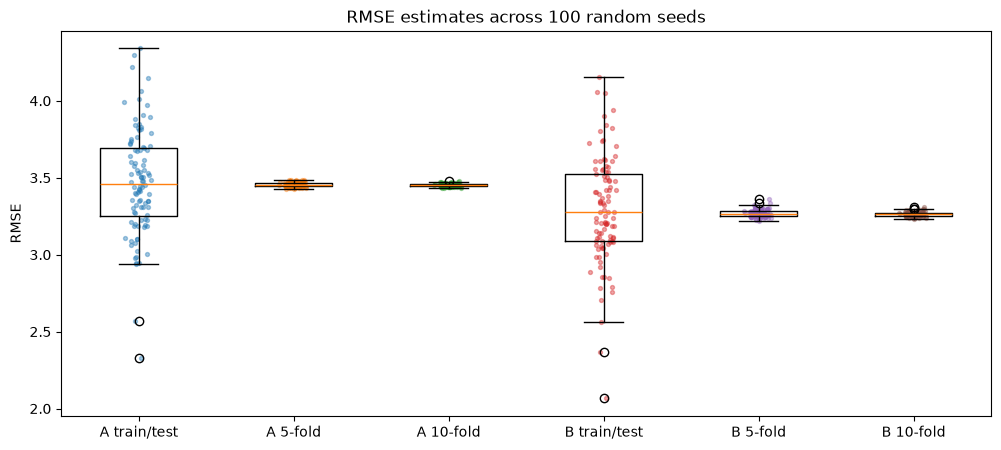

,mean,std,min,max
label,,,,
A train/test,3.472,0.344,2.331,4.340
A 5-fold,3.456,0.014,3.427,3.485
A 10-fold,3.454,0.009,3.431,3.482
B train/test,3.292,0.349,2.066,4.157
B 5-fold,3.269,0.024,3.222,3.364
B 10-fold,3.264,0.014,3.235,3.307


In [16]:
rows = []
for seed in range(100):
    for model_name in ["A", "B"]:
        if model_name == "A":
            model, Xm = model_a, X_a
        else:
            model, Xm = model_b, X_b
        X_tr, X_te, y_tr, y_te = train_test_split(Xm, y, test_size=0.2, random_state=seed)
        model.fit(X_tr, y_tr)
        rows.append({"model": model_name, "seed": seed, "method": "train/test",
                     "rmse": root_mean_squared_error(y_te, model.predict(X_te))})
        for method_name, n_splits in [("5-fold", 5), ("10-fold", 10)]:
            method = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
            mse = -cross_val_score(model, Xm, y, cv=method, scoring="neg_mean_squared_error")
            rows.append({"model": model_name, "seed": seed, "method": method_name,
                         "rmse": np.sqrt(mse.mean())})

by_seed = pd.DataFrame(rows)
by_seed["label"] = by_seed["model"] + " " + by_seed["method"]

order = ["A train/test", "A 5-fold", "A 10-fold", "B train/test", "B 5-fold", "B 10-fold"]

fig, ax = plt.subplots(figsize=(12, 5))
ax.boxplot([by_seed.loc[by_seed.label == m, "rmse"] for m in order], tick_labels=order)
for i, m in enumerate(order, start=1):
    vals = by_seed.loc[by_seed.label == m, "rmse"]
    ax.scatter(np.random.default_rng(0).normal(i, 0.04, len(vals)), vals, s=8, alpha=0.4)
ax.set(ylabel="RMSE", title="RMSE estimates across 100 random seeds")
plt.show()

by_seed.groupby("label")["rmse"].agg(["mean", "std", "min", "max"]).loc[order].round(3)


##### Part A


Model B is the best. Its means are lower than Model A's for all RMSEs, and for the 5-fold and 10-fold CV, Model B's max RMSE is lower than Model A's min RMSE.


##### Part B


Yes, the categorical variables only add two extra predictors to the model after one hot encoding, and they lower RMSE by about 0.2. That is well above the standard deviation of the 5-fold and 10-fold estimates, so the improvement is real and not noise.


# Part 3


### Question 1


In [17]:
bike = pd.read_csv("bike-sharing-daily.csv")

x1 = bike[["temp"]].values
yy = bike["cnt"].values

x1_tr, x1_te, y1_tr, y1_te = train_test_split(x1, yy, test_size=0.2, random_state=42)

grid = np.linspace(x1.min(), x1.max(), 200)[:, None]


##### Part A


In [18]:
model_lin = LinearRegression().fit(x1_tr, y1_tr)


##### Part B


In [19]:
model_poly = make_pipeline(StandardScaler(), PolynomialFeatures(9, include_bias=False), LinearRegression()).fit(x1_tr, y1_tr)


##### Part C


In [20]:
model_spline = make_pipeline(SplineTransformer(degree=3, n_knots=7, knots="quantile"), LinearRegression()).fit(x1_tr, y1_tr)


##### Part D


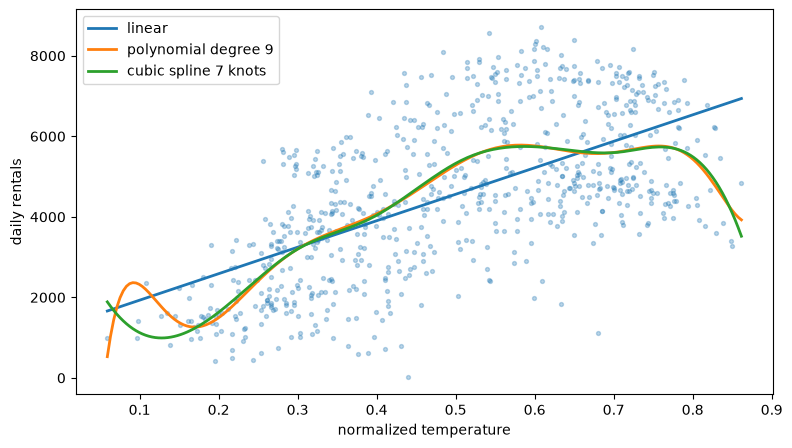

In [21]:
plt.figure(figsize=(9, 5))
plt.scatter(x1, yy, s=8, alpha=0.3)
plt.plot(grid, model_lin.predict(grid), lw=2, label="linear")
plt.plot(grid, model_poly.predict(grid), lw=2, label="polynomial degree 9")
plt.plot(grid, model_spline.predict(grid), lw=2, label="cubic spline 7 knots")
plt.xlabel("normalized temperature")
plt.ylabel("daily rentals")
plt.legend()


Both the polynomial and cubic spline curves are quite similar, with the only significant deviation being at the lowest temperatures where data is sparse. The linear curve, on the other hand, is similar in the middle temperatures but is highest at both low and high temperatures and doesn't show the same dips that the more extreme temperatures cause in the other models.


### Question 2


In [22]:
rows = []
for name, model in [("linear", model_lin),
                    ("polynomial degree 9", model_poly),
                    ("cubic spline 7 knots", model_spline)]:
    rows.append({"model": name,
                 "train RMSE": root_mean_squared_error(y1_tr, model.predict(x1_tr)),
                 "test RMSE": root_mean_squared_error(y1_te, model.predict(x1_te))})

pd.DataFrame(rows).set_index("model").round(2)


,train RMSE,test RMSE
model,,
linear,1497.67,1546.30
polynomial degree 9,1379.26,1531.56
cubic spline 7 knots,1380.57,1532.43


##### Part A


Polynomial has both the smallest test and train RMSE although cubic spline is very close.


##### Part B


Based on these results it does imply decreasing the test error, but the relationship is not 1 to 1. Test RMSE only decreases by about 15 while train RMSE decreases by about 118.


##### Part C


Both the polynomial and cubic spline have a pretty large gap between the test and train RMSE, about 152, which is evidence that they are overfitting on the training data. The linear model has a much smaller gap, about 49, but the highest RMSE of the three on both columns, which points to underfitting since its straight line can't capture the hump and dips in the data.


### Question 3


In [23]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for name, model in [("linear", model_lin),
                    ("polynomial degree 9", model_poly),
                    ("cubic spline 7 knots", model_spline)]:
    mse = -cross_val_score(model, x1, yy, cv=cv, scoring="neg_mean_squared_error")
    rows.append({"model": name,
                 "train RMSE": root_mean_squared_error(y1_tr, model.predict(x1_tr)),
                 "test RMSE": root_mean_squared_error(y1_te, model.predict(x1_te)),
                 "5-fold RMSE": np.sqrt(mse.mean())})

pd.DataFrame(rows).set_index("model").round(2)


,train RMSE,test RMSE,5-fold RMSE
model,,,
linear,1497.67,1546.30,1510.96
polynomial degree 9,1379.26,1531.56,1435.47
cubic spline 7 knots,1380.57,1532.43,1427.56


The 5-fold RMSE is lower than the test RMSE across the board, and very substantially for the polynomial and cubic spline. The overfitting gap closes quite a bit, from about 152 to about 50, so I am less concerned that they are overfitted. The polynomial and cubic spline 5-fold RMSE is now about 80 better than linear, compared to just 15 on the single test split, so I am more convinced they are better models than the linear model.

# Part 4


### Question 1


In [24]:
B = 500
rng = np.random.default_rng(42)
n_train = len(x1_tr)

rows = []
for b in range(B):
    idx = rng.integers(0, n_train, size=n_train)
    xb_tr, yb_tr = x1_tr[idx], y1_tr[idx]
    for name, model in [("linear", model_lin),
                        ("polynomial degree 9", model_poly),
                        ("cubic spline 7 knots", model_spline)]:
        rows.append({"model": name,
                     "pred": model.fit(xb_tr, yb_tr).predict([[0.60]])[0]})

boot = pd.DataFrame(rows)
boot.shape


(1500, 2)

<Axes: xlabel='model', ylabel='pred'>

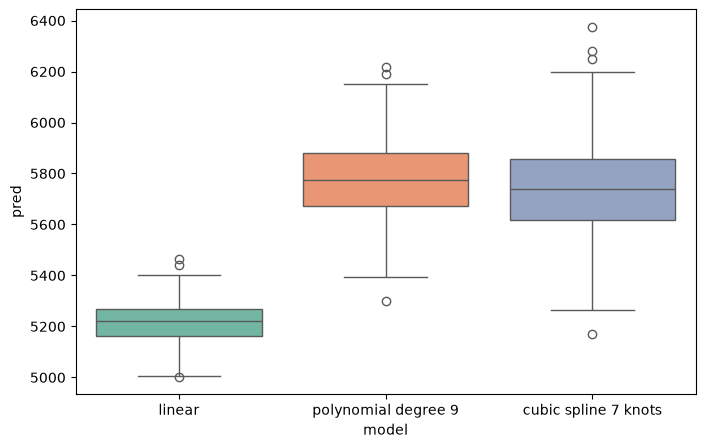

In [25]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=boot, x="model", y="pred", hue="model", palette="Set2", legend=False)


In [26]:
boot.groupby("model")["pred"].agg(["count", "mean", "std", "min", "max"]).round(1)


,count,mean,std,min,max
model,,,,,
cubic spline 7 knots,500,5743.7,179.6,5170.9,6376.4
linear,500,5217.1,74.5,5003.4,5466.1
polynomial degree 9,500,5775.3,149.4,5299.1,6218.7


##### Part A


Linear is the most stable and the cubic spline is the most variable. Across the 500 bootstrap samples the linear model's predictions only vary by about 75 while the cubic spline's vary by about 180, and the flexible models' predictions sit about 530 to 560 higher at temp 0.60.


##### Part B


Linear has a notably lower standard deviation than both flexible models, so the more flexible a model is the more sensitive it is to the training data.


##### Part C


This would suggest the model is heavily overfitting since different resamples are giving very different predictions. That would mean the model has very high variance and a limited potential to generalize.


### Question 2


##### Part A


Linear has the lowest variance but the highest bias since it can't adjust to local peaks and dips in the data. Both the polynomial and spline have higher variance but trade that off for lower bias and can adjust to the shape of the data. Between the polynomial and cubic spline, the cubic spline comes out the winner as it keeps almost the same low bias while avoiding the wild edges of the polynomial, giving it the lowest 5-fold RMSE.


##### Part B


First it matters a lot what data the RMSE is coming from. A low training RMSE could just mean extreme overfitting, meaning very high variance and very poor generalization. The teammate's rule also only accounts for bias on the training sample, since the smallest training RMSE is the smallest bias there, and ignores the variance side of the tradeoff. If they are looking at just the one pass test RMSE, that could just be from a lucky sample draw and the model could still have very high variance. By using a 5 or 10 fold CV for the RMSE you get a much more holistic picture of the model's RMSE under many different conditions, and then by using bootstrapping you can measure the actual distribution of the estimates to choose the best tradeoff between bias and variance.


AI acknowledgment

I used an AI assistant to help write code for this lab. I checked the outputs myself against the data and the class materials to make sure the code worked correctly. I also used AI to help with spelling and grammar in my written answers. All questions were answered in my own words.
